<center><h1>Zhang_Zhengshu_HW5</h1></center>
<br>
<br>

Name: Zhengshu Zhang
<br>
Github Username: forestzs
<br>
USC ID: 4664738582

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import math
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor

pd.set_option("display.width", 120)

### (a) Obtain Data

Get the Accute Inamations Data Set

For part (a), the Acute Inflammations files from the UCI Machine Learning Repository [1] are saved in the folder data/AcuteInflammations.

The file diagnosis.data is read in three steps. It is decoded as UTF-16 text (a text encoding with two bytes per character), and each line is split at the TAB characters. The comma in each temperature is then read as the decimal point, so "35,5" becomes 35.5.

The column names follow the order in diagnosis.names.

| Column | Meaning in diagnosis.names |
|---|---|
| temperature | Temperature of patient, in degrees Celsius |
| nausea | Occurrence of nausea |
| lumbar_pain | Lumbar pain |
| urine_pushing | Urine pushing (continuous need for urination) |
| micturition_pains | Micturition pains |
| burning_urethra | Burning of urethra, itch, swelling of urethra outlet |
| bladder | Decision 1, inflammation of urinary bladder |
| nephritis | Decision 2, nephritis of renal pelvis origin |

Every yes is encoded as 1 and every no as 0.

In [2]:
acute_cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains",
              "burning_urethra", "bladder", "nephritis"]
symptoms = acute_cols[1:6]
features_1 = acute_cols[:6]

# chr(9) is the TAB character, and decimal="," turns "35,5" into 35.5
acute = pd.read_csv("data/AcuteInflammations/diagnosis.data", encoding="utf-16", sep=chr(9),
                    header=None, names=acute_cols, decimal=",")
for col in acute_cols[1:]:
    acute[col] = acute[col].map({"yes": 1, "no": 0})

assert acute.notna().all().all()
print("shape:", acute.shape)
print("temperature from", acute["temperature"].min(), "to", acute["temperature"].max())
print(acute.dtypes.value_counts().to_string())
acute.head()

shape: (120, 8)
temperature from 35.5 to 41.5
int64      7
float64    1


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

For part (b), the two decisions are combined into one label with four classes, which is the label powerset method. The four classes are bladder only, nephritis only, neither and both.

Footnote 1 of the handout asks whether the label powerset method is more relevant here than binary relevance (one tree for each label), and the answer is yes. Both diseases occur together in 19 of the 120 patients (counts printed below), so one tree that predicts the four combinations learns them directly. Binary relevance would instead split the same information across two separate trees.

The tree uses the temperature and the five symptoms as features and is fitted on all 120 rows.

In [3]:
label_names = {(1, 0): "bladder only", (0, 1): "nephritis only", (0, 0): "neither", (1, 1): "both"}
acute["diagnosis"] = [label_names[(b, n)] for b, n in zip(acute["bladder"], acute["nephritis"])]
print(acute["diagnosis"].value_counts().to_string())

X1 = acute[features_1]
y1 = acute["diagnosis"]
full_tree = DecisionTreeClassifier(random_state=0).fit(X1, y1)
print()
print("depth:", full_tree.get_depth())
print("leaves:", full_tree.get_n_leaves())
print("training accuracy:", full_tree.score(X1, y1))

diagnosis
bladder only      40
nephritis only    31
neither           30
both              19

depth: 4
leaves: 6
training accuracy: 1.0


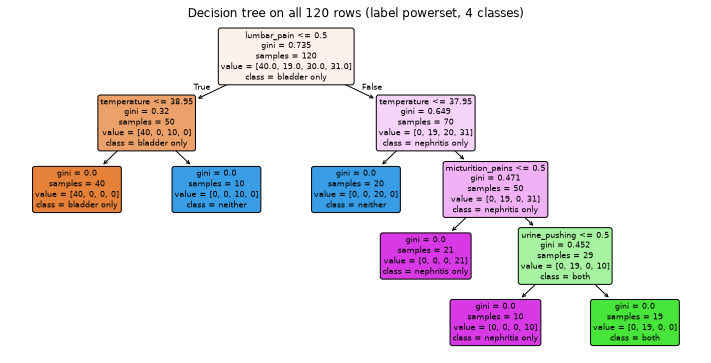

In [4]:
fig, ax = plt.subplots(figsize=(12.5, 6), dpi=72)
plot_tree(full_tree, feature_names=features_1, class_names=list(full_tree.classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Decision tree on all 120 rows (label powerset, 4 classes)")
plt.show()

### (c) Convert the decision rules

For part (c), the function below walks the tree from the root to every leaf and prints one IF-THEN rule for each leaf, with the number of rows in that leaf. The idea comes from the KDnuggets article in footnote 2 of the handout [3], but the code is written for this tree.

A split on a symptom is printed as "= no" or "= yes", because a threshold of 0.5 on a 0/1 feature only separates no from yes. The temperature thresholds keep two decimals, such as 38.95, because the tree splits halfway between two measured values. Rounded to one decimal, 38.95 would become 39.0 and put the patients at 39.0 on the wrong side of the split.

In [5]:
def tree_rules(model, feature_names, binary_features):
    t = model.tree_
    rules = []

    def walk(node, conditions):
        if t.children_left[node] == -1:
            leaf_class = model.classes_[np.argmax(t.value[node])]
            rules.append((conditions, leaf_class, int(t.n_node_samples[node])))
            return
        name = feature_names[t.feature[node]]
        threshold = t.threshold[node]
        if name in binary_features:
            assert threshold == 0.5
            left, right = name + " = no", name + " = yes"
        else:
            left, right = "%s <= %.2f" % (name, threshold), "%s > %.2f" % (name, threshold)
        walk(t.children_left[node], conditions + [left])
        walk(t.children_right[node], conditions + [right])

    walk(0, [])
    return rules


def print_rules(rules):
    for conditions, leaf_class, n_rows in rules:
        print("IF " + " AND ".join(conditions) + " THEN " + leaf_class + "   (" + str(n_rows) + " rows)")


full_rules = tree_rules(full_tree, features_1, symptoms)
print_rules(full_rules)

IF lumbar_pain = no AND temperature <= 38.95 THEN bladder only   (40 rows)
IF lumbar_pain = no AND temperature > 38.95 THEN neither   (10 rows)
IF lumbar_pain = yes AND temperature <= 37.95 THEN neither   (20 rows)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis only   (21 rows)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis only   (10 rows)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both   (19 rows)


### (d) Use cost-complexity pruning

For part (d), cost_complexity_pruning_path gives every value of the pruning parameter ccp_alpha at which the pruned tree changes. A larger ccp_alpha prunes more and gives a smaller tree. For each ccp_alpha, the table shows the number of leaves, the depth and the training accuracy of the tree fitted on all 120 rows, together with its cross-validation accuracy. The cross-validation accuracy comes from 5-fold stratified cross-validation on the four-class label and is the mean accuracy over the five held-out folds.

In [6]:
path = full_tree.cost_complexity_pruning_path(X1, y1)
alphas = path.ccp_alphas

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
pruning = []
for alpha in alphas:
    tree_a = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha).fit(X1, y1)
    fold_acc = cross_val_score(DecisionTreeClassifier(random_state=0, ccp_alpha=alpha), X1, y1, cv=folds)
    pruning.append([alpha, tree_a.get_n_leaves(), tree_a.get_depth(), tree_a.score(X1, y1), fold_acc.mean()])
pruning = pd.DataFrame(pruning, columns=["ccp_alpha", "leaves", "depth", "train_accuracy", "cross_val_accuracy"])
print(pruning.to_string(index=False, float_format="%.4f"))

 ccp_alpha  leaves  depth  train_accuracy  cross_val_accuracy
    0.0000       6      4          1.0000              0.9917
    0.0982       4      2          0.8417              0.8583
    0.1333       3      2          0.7583              0.7583
    0.1820       2      1          0.5917              0.6833
    0.2229       1      0          0.3333              0.4833


Among the values of ccp_alpha with the highest cross-validation accuracy, the largest one is taken, because the question asks for a minimal tree.

In [7]:
def choose_alpha(alpha_values, scores):
    alpha_values = np.asarray(alpha_values)
    scores = np.asarray(scores)
    best = np.isclose(scores, scores.max())
    return alpha_values[best].max()


best_alpha = choose_alpha(pruning["ccp_alpha"], pruning["cross_val_accuracy"])
pruned_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=best_alpha).fit(X1, y1)
print("chosen ccp_alpha:", best_alpha)
print("leaves:", pruned_tree.get_n_leaves())
print("depth:", pruned_tree.get_depth())
print("training accuracy:", pruned_tree.score(X1, y1))
print("same predictions as the full tree:", (pruned_tree.predict(X1) == full_tree.predict(X1)).all())

chosen ccp_alpha: 0.0
leaves: 6
depth: 4
training accuracy: 1.0
same predictions as the full tree: True


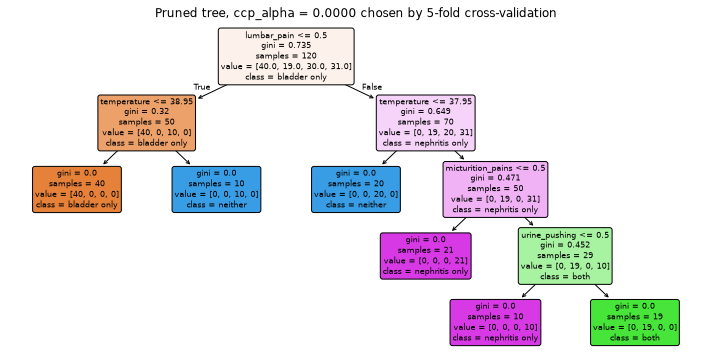

In [8]:
fig, ax = plt.subplots(figsize=(12.5, 6), dpi=72)
plot_tree(pruned_tree, feature_names=features_1, class_names=list(pruned_tree.classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Pruned tree, ccp_alpha = %.4f chosen by 5-fold cross-validation" % best_alpha)
plt.show()

In [9]:
print_rules(tree_rules(pruned_tree, features_1, symptoms))

IF lumbar_pain = no AND temperature <= 38.95 THEN bladder only   (40 rows)
IF lumbar_pain = no AND temperature > 38.95 THEN neither   (10 rows)
IF lumbar_pain = yes AND temperature <= 37.95 THEN neither   (20 rows)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis only   (21 rows)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis only   (10 rows)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both   (19 rows)


Cross-validation picks ccp_alpha = 0, so the pruned tree is the same as the full tree, with 6 leaves, depth 4 and a training accuracy of 1.0. Pruning the tree at all costs accuracy, because the cross-validation accuracy already drops from 0.9917 to 0.8583 at the next ccp_alpha on the path, 0.0982. The full tree is therefore already the minimal tree with the best cross-validation accuracy. The 6 rules printed above are easy to read because each rule has at most four conditions, and each condition is a yes or no symptom or a temperature limit.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

For part (a), the Communities and Crime files from the UCI Machine Learning Repository [2] are saved in the folder data/CommunitiesAndCrime.

The file communities.data has no header row, so the 128 column names are taken in order from the @attribute lines of communities.names. The target is ViolentCrimesPerPop, the last column. Missing values are written as a question mark in the file and are read as missing. The first 1495 rows are the train set and the remaining 499 rows are the test set, in file order as the handout says.

In [10]:
with open("data/CommunitiesAndCrime/communities.names") as f:
    crime_cols = [line.split()[1] for line in f if line.startswith("@attribute")]
print("number of columns:", len(crime_cols), " last column:", crime_cols[-1])

crime = pd.read_csv("data/CommunitiesAndCrime/communities.data", header=None, names=crime_cols, na_values="?")
print("data:", crime.shape)

train = crime.iloc[:1495]
test = crime.iloc[1495:]
print("train:", train.shape)
print("test:", test.shape)

number of columns: 128  last column: ViolentCrimesPerPop
data: (1994, 128)
train: (1495, 128)
test: (499, 128)


### (b) Missing values

For part (b), the five columns state, county, community, communityname and fold are dropped. The data description calls them "not predictive" because state, county and community are numeric codes, communityname is "for information only" and fold is the "fold number for non-random 10 fold cross validation". Without these five columns and the target ViolentCrimesPerPop, 122 features remain.

In [11]:
non_predictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
features_2 = [c for c in crime_cols if c not in non_predictive + [target]]
print("number of features:", len(features_2))

X_train, y_train = train[features_2], train[target]
X_test, y_test = test[features_2], test[target]

missing = pd.DataFrame({"train": X_train.isna().sum(), "test": X_test.isna().sum()})
missing["total"] = missing["train"] + missing["test"]
missing = missing[missing["total"] > 0].sort_values("total", ascending=False)
print("features with missing values:", len(missing))
print(missing.to_string())
print("missing values in the target:", crime[target].isna().sum())

number of features: 122
features with missing values: 23
                      train  test  total
LemasSwornFT           1256   419   1675
LemasSwFTPerPop        1256   419   1675
LemasSwFTFieldOps      1256   419   1675
LemasTotalReq          1256   419   1675
LemasSwFTFieldPerPop   1256   419   1675
LemasTotReqPerPop      1256   419   1675
PolicReqPerOffic       1256   419   1675
OfficAssgnDrugUnits    1256   419   1675
PolicPerPop            1256   419   1675
RacialMatchCommPol     1256   419   1675
PctPolicWhite          1256   419   1675
PctPolicBlack          1256   419   1675
PctPolicHisp           1256   419   1675
PctPolicAsian          1256   419   1675
PctPolicMinor          1256   419   1675
PolicOperBudg          1256   419   1675
NumKindsDrugsSeiz      1256   419   1675
PolicAveOTWorked       1256   419   1675
PolicCars              1256   419   1675
LemasGangUnitDeploy    1256   419   1675
LemasPctPolicOnPatr    1256   419   1675
PolicBudgPerPop        1256   419   1675


The missing values in the table above are filled with the median of each feature, computed on the train set only, and the same train medians fill both the train set and the test set. The median is used because many features are skewed, and a few extreme values pull the mean but not the median. Only the train set is used because the test set must not influence anything the models of parts (f) to (j) are built from.

In [12]:
imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
imputer.fit(X_train)
X_train_imp = imputer.transform(X_train)
X_test_imp = imputer.transform(X_test)

assert X_train_imp.notna().all().all()
assert X_test_imp.notna().all().all()
print("missing values left in train:", X_train_imp.isna().sum().sum())
print("missing values left in test:", X_test_imp.isna().sum().sum())

train_medians = pd.Series(imputer.statistics_, index=features_2)
print()
print("train medians used for the features with missing values")
print(train_medians[missing.index].to_string())

missing values left in train: 0
missing values left in test: 0

train medians used for the features with missing values
LemasSwornFT            0.02
LemasSwFTPerPop         0.18
LemasSwFTFieldOps       0.97
LemasTotalReq           0.04
LemasSwFTFieldPerPop    0.21
LemasTotReqPerPop       0.17
PolicReqPerOffic        0.30
OfficAssgnDrugUnits     0.04
PolicPerPop             0.18
RacialMatchCommPol      0.73
PctPolicWhite           0.77
PctPolicBlack           0.12
PctPolicHisp            0.05
PctPolicAsian           0.00
PctPolicMinor           0.20
PolicOperBudg           0.03
NumKindsDrugsSeiz       0.57
PolicAveOTWorked        0.28
PolicCars               0.07
LemasGangUnitDeploy     0.50
LemasPctPolicOnPatr     0.76
PolicBudgPerPop         0.15
OtherPerCap             0.25


Most of the missing values are in 22 features about the local police department, such as LemasSwornFT, the number of sworn full time police officers. Each of these police features is missing in 1675 of the 1994 rows, so most of its values after imputation are the same train median.

From here on, the data set in parts (c), (d) and (e) means all 1994 rows after imputation, because these three parts only describe the features and fit no model.

In [13]:
X_all = pd.concat([X_train_imp, X_test_imp])
y_all = crime[target]
print("data set for parts (c) to (e):", X_all.shape)

data set for parts (c) to (e): (1994, 122)


### (c) Plot a correlation matrix

For part (c), the heat map shows the Pearson correlation between every pair of the 122 features. Not every name fits on the axes, so only every tenth feature name is shown as a tick label.

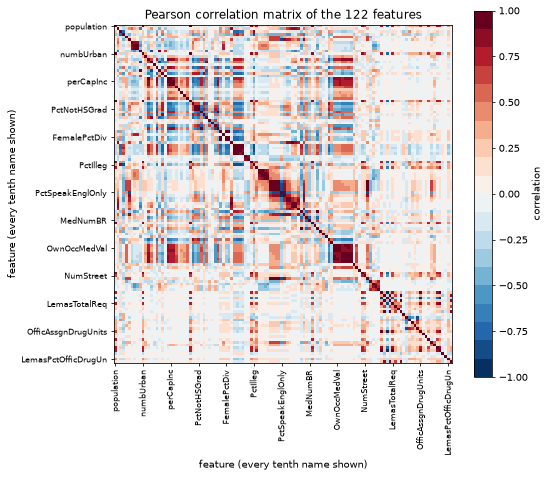

In [14]:
corr = X_all.corr()

fig, ax = plt.subplots(figsize=(7.8, 6.8), dpi=70)
im = ax.imshow(corr.values, cmap=plt.get_cmap("RdBu_r", 20), vmin=-1, vmax=1, interpolation="nearest")
ticks = list(range(0, len(features_2), 10))
ax.set_xticks(ticks)
ax.set_xticklabels([features_2[i] for i in ticks], rotation=90, fontsize=8)
ax.set_yticks(ticks)
ax.set_yticklabels([features_2[i] for i in ticks], fontsize=8)
ax.set_xlabel("feature (every tenth name shown)")
ax.set_ylabel("feature (every tenth name shown)")
ax.set_title("Pearson correlation matrix of the 122 features")
fig.colorbar(im, ax=ax, label="correlation")
plt.show()

In [15]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().reset_index()
pairs.columns = ["feature_1", "feature_2", "correlation"]
pairs["abs_correlation"] = pairs["correlation"].abs()
top_pairs = pairs.sort_values("abs_correlation", ascending=False).head(5)
print(top_pairs.to_string(index=False, float_format="%.4f"))

      feature_1     feature_2  correlation  abs_correlation
LemasSwFTPerPop   PolicPerPop       1.0000           1.0000
   PctRecImmig8 PctRecImmig10       0.9955           0.9955
 OwnOccLowQuart  OwnOccMedVal       0.9945           0.9945
   PctRecImmig5  PctRecImmig8       0.9934           0.9934
     population     numbUrban       0.9931           0.9931


The heat map shows several dark red blocks along the diagonal, which are groups of related features with strong positive correlation. Examples are the income features near perCapInc, the house value features near OwnOccMedVal and the police features near LemasTotalReq. Dark blue areas, in contrast, show strong negative correlation between some groups, for example between the income features near perCapInc and the features near PctNotHSGrad. The five pairs printed above all have an absolute correlation above 0.99, and LemasSwFTPerPop and PolicPerPop have a correlation of 1.0000, so some features carry almost the same information.

### (d) Calculate the Coefficient of Variation CV

For part (d), the coefficient of variation is CV = s / m, where s is the sample standard deviation and m is the sample mean of a feature. The sample standard deviation divides the sum of squared deviations by n - 1, with n the number of rows, and numpy does this with ddof = 1. CV is computed for each of the 122 features over the 1994 imputed rows. The code also checks for features with a mean of 0, which have no CV and would be left out.

In [16]:
def coef_variation(x):
    x = np.asarray(x, dtype=float)
    return np.std(x, ddof=1) / np.mean(x)


means = X_all.mean()
print("features with a mean of 0:", list(means[means == 0].index))

cv_table = pd.Series({f: coef_variation(X_all[f]) for f in features_2 if means[f] != 0}, name="CV")
cv_table = cv_table.sort_values(ascending=False)
print("number of CV values:", len(cv_table))
print(cv_table.to_frame().to_string(float_format="%.4f"))
print()
print("PctPolicAsian train median:", train_medians["PctPolicAsian"])
print("PctPolicAsian values equal to 0:", (X_all["PctPolicAsian"] == 0).sum(), "of", len(X_all))

features with a mean of 0: []
number of CV values: 122
                          CV
PctPolicAsian         5.4478
NumStreet             4.4077
NumInShelters         3.4855
NumIlleg              2.9942
NumImmig              2.9005
LemasPctOfficDrugUn   2.5553
NumUnderPov           2.3050
population            2.2035
LemasSwornFT          2.0807
numbUrban             2.0017
HousVacant            1.9588
LandArea              1.6780
racePctHisp           1.6143
PolicOperBudg         1.5629
PctNotSpeakEnglWell   1.4591
PctUsePubTrans        1.4167
racepctblack          1.4109
LemasTotalReq         1.3817
racePctAsian          1.3592
PctPolicHisp          1.3263
PctRecentImmig        1.3001
PctRecImmig5          1.2976
PctRecImmig10         1.2840
PctRecImmig8          1.2812
PctPersDenseHous      1.1272
OfficAssgnDrugUnits   1.0886
PolicCars             1.0876
PctForeignBorn        1.0723
PctVacantBoarded      1.0647
PctIlleg              0.9198
PctHousNoPhone        0.9182
OwnOccMedVal     

PctPolicAsian has the highest CV because 1864 of its 1994 values are 0, which makes its mean small. Most of these zeros come from the imputation, because the train median of PctPolicAsian is 0 and its 1675 missing values were filled with that median.

### (e) Scatter plots and box plots for highest CV features

For part (e), the 11 features with the highest CV are plotted, because 11 is floor(sqrt(128)), the square root of 128 rounded down. Each scatter plot shows one feature on the x axis against ViolentCrimesPerPop on the y axis.

k = 11
                        CV
PctPolicAsian       5.4478
NumStreet           4.4077
NumInShelters       3.4855
NumIlleg            2.9942
NumImmig            2.9005
LemasPctOfficDrugUn 2.5553
NumUnderPov         2.3050
population          2.2035
LemasSwornFT        2.0807
numbUrban           2.0017
HousVacant          1.9588


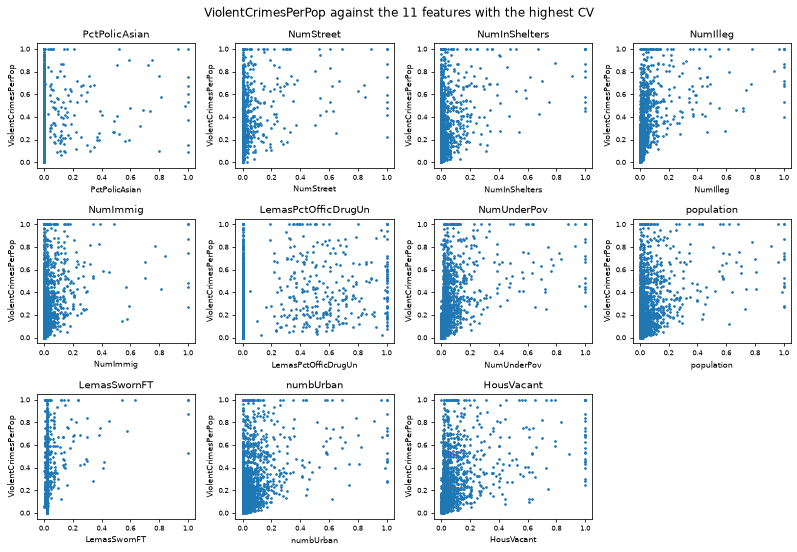

In [17]:
k = math.floor(math.sqrt(128))
top_cv = list(cv_table.index[:k])
print("k =", k)
print(cv_table.head(k).to_frame().to_string(float_format="%.4f"))

fig, axes = plt.subplots(3, 4, figsize=(11.5, 8), dpi=70)
for ax, f in zip(axes.flat, top_cv):
    ax.scatter(X_all[f], y_all, s=3)
    ax.set_title(f, fontsize=10)
    ax.set_xlabel(f, fontsize=8)
    ax.set_ylabel(target, fontsize=8)
    ax.tick_params(labelsize=7)
axes.flat[-1].axis("off")
fig.suptitle("ViolentCrimesPerPop against the 11 features with the highest CV")
fig.tight_layout()
plt.show()

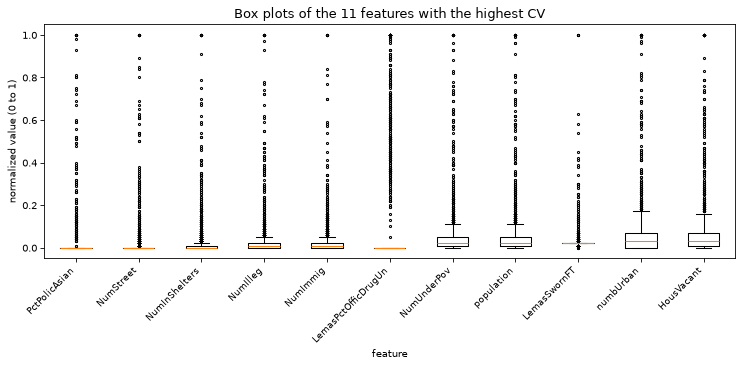

In [18]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=75)
ax.boxplot([X_all[f] for f in top_cv], flierprops={"markersize": 2})
ax.set_xticks(range(1, k + 1))
ax.set_xticklabels(top_cv, rotation=45, ha="right", fontsize=9)
ax.set_xlabel("feature")
ax.set_ylabel("normalized value (0 to 1)")
ax.set_title("Box plots of the 11 features with the highest CV")
fig.tight_layout()
plt.show()

No conclusion about the significance of the 11 features can be drawn from the scatter plots alone. A scatter plot shows the shape and spread of one feature against ViolentCrimesPerPop, but not whether the effect of that feature is statistically significant once the other features are in the model. Also, a high CV only means that a feature varies a lot relative to its mean, not that the feature predicts the target.

Both kinds of plot show that most values of each of the 11 features are close to 0. For PctPolicAsian, LemasPctOfficDrugUn and LemasSwornFT many points lie on one vertical line, while ViolentCrimesPerPop on that line spreads from 0 to 1.

### (f) Fit a linear model

For parts (f) to (j), every model is fitted on the imputed train set and evaluated on the imputed test set. The test error is the mean squared error (MSE) on the test set, which is the mean of the squared differences between the true and the predicted ViolentCrimesPerPop.

Every tuning parameter is chosen by 10-fold cross-validation on the train set, with the same folds for every model, and the test set is never used in any choice. Ten folds is a common choice for a train set of this size, because each fit during cross-validation still uses about 1345 of the 1495 rows. After each search over a grid of candidate values, the code checks that the chosen value is not at either end of the grid, since the best value could then lie outside the grid.

For part (f), least squares is fitted on all 122 features.

In [19]:
folds = KFold(n_splits=10, shuffle=True, random_state=0)


def test_mse(model):
    return mean_squared_error(y_test, model.predict(X_test_imp))


def train_mse(model):
    return mean_squared_error(y_train, model.predict(X_train_imp))


def on_grid_edge(grid, chosen):
    grid = list(grid)
    edge = chosen == min(grid) or chosen == max(grid)
    if edge:
        print("chosen value", chosen, "is on the edge of the grid")
    else:
        print("chosen value is inside the grid, which runs from", min(grid), "to", max(grid))
    return edge


ols = LinearRegression().fit(X_train_imp, y_train)
print("least squares test MSE:  %.10f" % test_mse(ols))
print("least squares train MSE: %.10f" % train_mse(ols))

least squares test MSE:  0.0179662154
least squares train MSE: 0.0162924323


### (g) Fit a ridge regression model

For part (g), ridge regression adds a penalty to the least squares loss, equal to lambda times the sum of the squared coefficients. scikit-learn calls the handout's lambda "alpha", so the grid of 61 values of lambda from 0.001 to 1000 on a log scale is passed to Ridge as alpha.

In [20]:
ridge_grid = np.logspace(-3, 3, 61)
ridge_search = GridSearchCV(Ridge(), {"alpha": ridge_grid}, cv=folds, scoring="neg_mean_squared_error")
ridge_search.fit(X_train_imp, y_train)
ridge_lambda = ridge_search.best_params_["alpha"]

on_grid_edge(ridge_grid, ridge_lambda)
print("chosen lambda:", ridge_lambda)
print("cross-validation MSE: %.10f" % -ridge_search.best_score_)
print("ridge test MSE:  %.10f" % test_mse(ridge_search))
print("ridge train MSE: %.10f" % train_mse(ridge_search))

chosen value is inside the grid, which runs from 0.001 to 1000.0
chosen lambda: 2.5118864315095824
cross-validation MSE: 0.0190838887
ridge test MSE:  0.0175059148
ridge train MSE: 0.0170144076


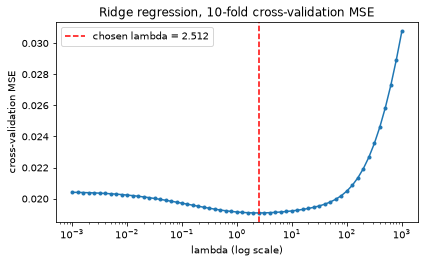

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 3.6), dpi=72)
ax.plot(ridge_grid, -ridge_search.cv_results_["mean_test_score"], marker=".")
ax.axvline(ridge_lambda, color="red", linestyle="--", label="chosen lambda = %.3f" % ridge_lambda)
ax.set_xscale("log")
ax.set_xlabel("lambda (log scale)")
ax.set_ylabel("cross-validation MSE")
ax.set_title("Ridge regression, 10-fold cross-validation MSE")
ax.legend()
plt.show()

Cross-validation chooses lambda = 2.512, which is inside the grid. Ridge gives a test MSE of 0.017506, slightly lower than the 0.017966 of least squares. On the train set, however, ridge has a slightly higher MSE than least squares, 0.017014 against 0.016292, because the penalty shrinks the coefficients. The cross-validation MSE falls slowly from lambda = 0.001 to the chosen lambda and rises quickly for lambda above about 100, where the penalty shrinks the coefficients too much.

### (h) Fit a LASSO model

For part (h), the LASSO (least absolute shrinkage and selection operator) adds a penalty to the least squares loss, equal to lambda times the sum of the absolute values of the coefficients. This penalty sets some coefficients exactly to 0, and the selected variables are the features whose coefficient is not 0. The value of lambda (alpha in scikit-learn) is chosen from 61 values between 0.000001 and 1 on a log scale, first on the raw features and then on standardized features.

In [22]:
lasso_grid = np.logspace(-6, 0, 61)
lasso_search = GridSearchCV(Lasso(max_iter=100000), {"alpha": lasso_grid}, cv=folds,
                            scoring="neg_mean_squared_error")
lasso_search.fit(X_train_imp, y_train)
lasso_lambda = lasso_search.best_params_["alpha"]

lasso_coef = pd.Series(lasso_search.best_estimator_.coef_, index=features_2)
lasso_vars = list(lasso_coef.index[lasso_coef != 0])

on_grid_edge(lasso_grid, lasso_lambda)
print("raw features, chosen lambda:", lasso_lambda)
print("cross-validation MSE: %.10f" % -lasso_search.best_score_)
print("LASSO (raw) test MSE:  %.10f" % test_mse(lasso_search))
print("LASSO (raw) train MSE: %.10f" % train_mse(lasso_search))
print("number of selected variables:", len(lasso_vars))
print()
print(textwrap.fill(", ".join(lasso_vars), width=100))

chosen value is inside the grid, which runs from 1e-06 to 1.0
raw features, chosen lambda: 0.0001
cross-validation MSE: 0.0190412865
LASSO (raw) test MSE:  0.0176586764
LASSO (raw) train MSE: 0.0168610005
number of selected variables: 75

racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf,
pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap,
AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy,
PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par,
PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10,
PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup,
PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded,
PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent,
MedRentPctHousInc, MedOwnC

For the standardized features, StandardScaler subtracts the mean of each feature and divides by its standard deviation. StandardScaler and the LASSO form one Pipeline, a chain of steps that is fitted as one model. During cross-validation the scaler is therefore fitted only on the nine folds used to fit the model, not on the held-out fold.

In [23]:
std_lasso = Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(max_iter=100000))])
std_search = GridSearchCV(std_lasso, {"lasso__alpha": lasso_grid}, cv=folds, scoring="neg_mean_squared_error")
std_search.fit(X_train_imp, y_train)
std_lambda = std_search.best_params_["lasso__alpha"]

std_coef = pd.Series(std_search.best_estimator_.named_steps["lasso"].coef_, index=features_2)
std_vars = list(std_coef.index[std_coef != 0])

on_grid_edge(lasso_grid, std_lambda)
print("standardized features, chosen lambda:", std_lambda)
print("cross-validation MSE: %.10f" % -std_search.best_score_)
print("LASSO (standardized) test MSE:  %.10f" % test_mse(std_search))
print("LASSO (standardized) train MSE: %.10f" % train_mse(std_search))
print("number of selected variables:", len(std_vars))
print()
print(textwrap.fill(", ".join(std_vars), width=100))

chosen value is inside the grid, which runs from 1e-06 to 1.0
standardized features, chosen lambda: 0.0006309573444801936
cross-validation MSE: 0.0191879250
LASSO (standardized) test MSE:  0.0177229361
LASSO (standardized) train MSE: 0.0169024511
number of selected variables: 76

racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc,
pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap,
OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu,
MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par,
PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10,
PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PctPersOwnOccup,
PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded,
PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLow

In [24]:
shared_vars = [f for f in lasso_vars if f in std_vars]
print("selected by both:", len(shared_vars))
print("only raw:", [f for f in lasso_vars if f not in std_vars])
print("only standardized:", [f for f in std_vars if f not in lasso_vars])

selected by both: 73
only raw: ['agePct65up', 'PctBSorMore']
only standardized: ['PctImmigRecent', 'PersPerOwnOccHous', 'OfficAssgnDrugUnits']


The two LASSO models have almost the same test MSE, 0.017659 on the raw features and 0.017723 on the standardized features. Cross-validation chooses lambda = 0.0001 for the raw features and lambda = 0.000631 for the standardized features, but the two values of lambda are not on the same scale because the features are not on the same scale. The raw model keeps 75 variables and the standardized model keeps 76, and 73 variables are in both lists. The features are already normalized to the range 0 to 1 (footnote 4 of the handout). Even so, the two models differ a little, because standardizing gives every feature the same standard deviation, which changes how hard the same penalty pushes on each coefficient.

### (i) Fit a PCR model

For part (i), principal components regression (PCR) replaces the 122 features by their first M principal components from principal component analysis (PCA), and then fits least squares on those M components. The features are standardized before PCA so that the principal components are not driven by the scale of the features, as in An Introduction to Statistical Learning [19]. The scaler, PCA and least squares form one Pipeline, so the scaler and PCA are fitted only on the nine folds used to fit the model. M is chosen from 1 to 122 by the same cross-validation.

In [25]:
pcr = Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("ols", LinearRegression())])
m_grid = list(range(1, len(features_2) + 1))
pcr_search = GridSearchCV(pcr, {"pca__n_components": m_grid}, cv=folds, scoring="neg_mean_squared_error")
pcr_search.fit(X_train_imp, y_train)
pcr_m = pcr_search.best_params_["pca__n_components"]
pcr_cv = -pcr_search.cv_results_["mean_test_score"]

on_grid_edge(m_grid, pcr_m)
print("chosen M:", pcr_m)
print("cross-validation MSE: %.10f" % -pcr_search.best_score_)
print("PCR test MSE:  %.10f" % test_mse(pcr_search))
print("PCR train MSE: %.10f" % train_mse(pcr_search))
print()
for m in [1, 5, 10, 20, 40, 60, 80, pcr_m, 122]:
    print("M = %3d   cross-validation MSE %.6f" % (m, pcr_cv[m - 1]))

chosen value is inside the grid, which runs from 1 to 122
chosen M: 95
cross-validation MSE: 0.0195305081
PCR test MSE:  0.0182963454
PCR train MSE: 0.0166324923

M =   1   cross-validation MSE 0.031445
M =   5   cross-validation MSE 0.026192
M =  10   cross-validation MSE 0.021035
M =  20   cross-validation MSE 0.020463
M =  40   cross-validation MSE 0.020107
M =  60   cross-validation MSE 0.019742
M =  80   cross-validation MSE 0.020292
M =  95   cross-validation MSE 0.019531
M = 122   cross-validation MSE 0.020441


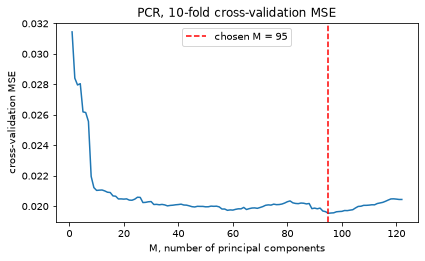

In [26]:
fig, ax = plt.subplots(figsize=(6.5, 3.6), dpi=72)
ax.plot(m_grid, pcr_cv)
ax.axvline(pcr_m, color="red", linestyle="--", label="chosen M = %d" % pcr_m)
ax.set_xlabel("M, number of principal components")
ax.set_ylabel("cross-validation MSE")
ax.set_title("PCR, 10-fold cross-validation MSE")
ax.legend()
plt.show()

Cross-validation chooses M = 95, which is inside the grid, and PCR gives a test MSE of 0.018296, the highest of the linear models. The cross-validation curve drops quickly over the first 10 components, from 0.031445 at M = 1 to 0.021035 at M = 10. It then stays almost flat near 0.020, with its lowest value of 0.019531 at M = 95.

### (j) Fit a boosting tree

For part (j), the boosting tree is fitted with XGBRegressor from XGBoost [18], which adds small regression trees one at a time and fits each new tree to the errors of the trees before it. The L1 penalty adds alpha times the sum of the absolute leaf values of each tree to the loss, where alpha is the XGBoost parameter reg_alpha. This alpha is the regularization term of part (j) in the handout and is not the lambda of ridge and the LASSO. The penalty pushes the leaf values of each tree toward 0, so each new tree changes the predictions less. Only alpha is tuned, as the handout asks, and the other settings are fixed and printed below.

In [27]:
xgb_settings = {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 3,
                "random_state": 0, "n_jobs": 1, "tree_method": "hist"}
print("fixed settings:", xgb_settings)

xgb_grid = [0.0] + list(np.logspace(-4, 1, 11))
xgb_search = GridSearchCV(XGBRegressor(**xgb_settings), {"reg_alpha": xgb_grid}, cv=folds,
                          scoring="neg_mean_squared_error")
xgb_search.fit(X_train_imp, y_train)
xgb_alpha = xgb_search.best_params_["reg_alpha"]
xgb_cv = -xgb_search.cv_results_["mean_test_score"]
xgb_used = len(xgb_search.best_estimator_.get_booster().get_score(importance_type="weight"))

on_grid_edge(xgb_grid, xgb_alpha)
print("chosen alpha:", xgb_alpha)
print("cross-validation MSE: %.10f" % -xgb_search.best_score_)
print("XGBoost test MSE:  %.10f" % test_mse(xgb_search))
print("XGBoost train MSE: %.10f" % train_mse(xgb_search))
print("features used in at least one split:", xgb_used)
print()
for a, s in zip(xgb_grid, xgb_cv):
    print("alpha = %-10.4g cross-validation MSE %.6f" % (a, s))

fixed settings: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 3, 'random_state': 0, 'n_jobs': 1, 'tree_method': 'hist'}


chosen value is inside the grid, which runs from 0.0 to 10.0
chosen alpha: 1.0
cross-validation MSE: 0.0193618597
XGBoost test MSE:  0.0162401629
XGBoost train MSE: 0.0077878363
features used in at least one split: 108

alpha = 0          cross-validation MSE 0.019522
alpha = 0.0001     cross-validation MSE 0.019450
alpha = 0.0003162  cross-validation MSE 0.019467
alpha = 0.001      cross-validation MSE 0.019519
alpha = 0.003162   cross-validation MSE 0.019514
alpha = 0.01       cross-validation MSE 0.019773
alpha = 0.03162    cross-validation MSE 0.019584
alpha = 0.1        cross-validation MSE 0.019568
alpha = 0.3162     cross-validation MSE 0.019470
alpha = 1          cross-validation MSE 0.019362
alpha = 3.162      cross-validation MSE 0.019485
alpha = 10         cross-validation MSE 0.021110


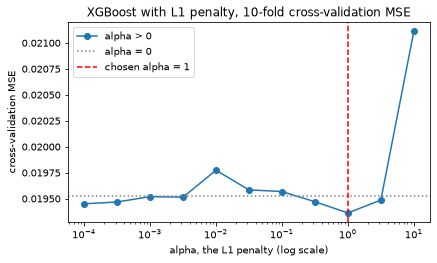

In [28]:
fig, ax = plt.subplots(figsize=(6.5, 3.6), dpi=72)
ax.plot(xgb_grid[1:], xgb_cv[1:], marker="o", label="alpha > 0")
ax.axhline(xgb_cv[0], color="gray", linestyle=":", label="alpha = 0")
ax.axvline(xgb_alpha, color="red", linestyle="--", label="chosen alpha = %g" % xgb_alpha)
ax.set_xscale("log")
ax.set_xlabel("alpha, the L1 penalty (log scale)")
ax.set_ylabel("cross-validation MSE")
ax.set_title("XGBoost with L1 penalty, 10-fold cross-validation MSE")
ax.legend()
plt.show()

Cross-validation chooses alpha = 1, which is inside the grid. The cross-validation MSE changes very little for alpha from 0 to 3.162, staying between 0.019362 and 0.019773, and rises to 0.021110 at alpha = 10, where the penalty shrinks the leaf values too much. XGBoost gives a test MSE of 0.016240 and a train MSE of 0.007788, so it fits the train set much more closely than the test set.

The table below compares the models of parts (f) to (j). In the "variables used" column, PCR counts all 122 features because they all enter through the M components, and XGBoost counts the features used in at least one split. The cross-validation MSE is the mean over the same 10 folds at the chosen value. Least squares has no tuning parameter and is scored on the same folds.

In [29]:
ols_cv = -cross_val_score(LinearRegression(), X_train_imp, y_train, cv=folds,
                          scoring="neg_mean_squared_error").mean()
summary = pd.DataFrame([
    ["least squares", "none", "-", len(features_2), ols_cv, test_mse(ols), train_mse(ols)],
    ["ridge", "lambda", "%.4g" % ridge_lambda, len(features_2), -ridge_search.best_score_,
     test_mse(ridge_search), train_mse(ridge_search)],
    ["LASSO, raw features", "lambda", "%.4g" % lasso_lambda, len(lasso_vars), -lasso_search.best_score_,
     test_mse(lasso_search), train_mse(lasso_search)],
    ["LASSO, standardized features", "lambda", "%.4g" % std_lambda, len(std_vars), -std_search.best_score_,
     test_mse(std_search), train_mse(std_search)],
    ["PCR", "M", str(pcr_m), len(features_2), -pcr_search.best_score_,
     test_mse(pcr_search), train_mse(pcr_search)],
    ["XGBoost, L1 penalty", "alpha", "%.4g" % xgb_alpha, xgb_used, -xgb_search.best_score_,
     test_mse(xgb_search), train_mse(xgb_search)],
], columns=["model", "tuning parameter", "chosen value", "variables used", "cross-validation MSE",
            "test MSE", "train MSE"])
print(summary.to_string(index=False, float_format="%.6f"))

                       model tuning parameter chosen value  variables used  cross-validation MSE  test MSE  train MSE
               least squares             none            -             122              0.020441  0.017966   0.016292
                       ridge           lambda        2.512             122              0.019084  0.017506   0.017014
         LASSO, raw features           lambda       0.0001              75              0.019041  0.017659   0.016861
LASSO, standardized features           lambda     0.000631              76              0.019188  0.017723   0.016902
                         PCR                M           95             122              0.019531  0.018296   0.016632
         XGBoost, L1 penalty            alpha            1             108              0.019362  0.016240   0.007788


XGBoost has the lowest test MSE, 0.016240, while the linear models lie between 0.017506 (ridge) and 0.018296 (PCR). However, XGBoost does not have the lowest cross-validation MSE, 0.019362 against 0.019084 for ridge and 0.019041 for the raw LASSO, so its lead on the test set may partly depend on this particular test set. The differences between the linear models are small, at most 0.000790 in test MSE, so none of the linear models is clearly better than the others. The LASSO reaches about the same test MSE as ridge and least squares with only 75 or 76 of the 122 features, which makes it the easiest of the linear models to interpret.

## References

[1] UCI Machine Learning Repository, Acute Inflammations data set. https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations

[2] UCI Machine Learning Repository, Communities and Crime data set. https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime

[3] KDnuggets, Simplifying Decision Tree Interpretability with Python and Scikit-learn. https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html

[4] scikit-learn, DecisionTreeClassifier. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

[5] scikit-learn, plot_tree. https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html

[6] scikit-learn, Post pruning decision trees with cost complexity pruning. https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html

[7] scikit-learn, StratifiedKFold. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

[8] scikit-learn, cross_val_score. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html

[9] scikit-learn, SimpleImputer. https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html

[10] scikit-learn, LinearRegression. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

[11] scikit-learn, Ridge. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

[12] scikit-learn, Lasso. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html

[13] scikit-learn, GridSearchCV. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

[14] scikit-learn, KFold. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html

[15] scikit-learn, Pipeline. https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

[16] scikit-learn, StandardScaler. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

[17] scikit-learn, PCA. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

[18] XGBoost, Python API reference, XGBRegressor. https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor

[19] G. James, D. Witten, T. Hastie and R. Tibshirani, An Introduction to Statistical Learning, second edition. https://www.statlearning.com/